# 01 · Data cleaning & feature engineering

**SteelScope**: composition-to-performance intelligence for steels & iron alloys.

This notebook runs the reusable pipeline in `src/analysis/cleaning.py` and shows the evidence behind
each decision. No cleaning logic lives here: if a number below changes, it changed in the pipeline.

**Unit of analysis.** The raw file lists each grade up to twice (a spaced and a hyphenated name).
After the investigation below, the analysis unit is the **canonical grade**: one row per grade, with
tensile strength taken only from measured listings.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

from src.analysis import plotting as P
P.apply_theme()

def show(fig, name):
    path = P.save(fig, name)
    display(Image(filename=str(path)))

## 1 · Run the pipeline

Every step records the row count before and after.

In [2]:
from src.analysis.cleaning import run_cleaning, save_outputs, canonical_key
from src.analysis.constants import ELEMENTS, RAW_TS, IMPUTED_TS_VALUE
result = run_cleaning()
grades, listings, log = result.grades, result.listings, result.log
log.to_frame()

,step,rows_before,rows_after,delta,detail
0,load_raw,0,2672,2672,Read Alloys.csv: 2672 rows x 34 columns
1,validate_schema,2672,2672,0,"34 expected columns present, all numeric, 0 nulls, no negative wt%"
2,drop_exact_duplicates,2672,2610,-62,Removed 62 exact full-row duplicates
3,flag_imputed_ts,2610,2610,0,"469 rows (18.0%) carry TS = 652.482978 (the raw column mean); flagged, not d..."
4,add_canonical_grade,2610,2610,0,"1389 canonical grades; 1221 listed twice (spaced + hyphenated name), 168 lis..."
5,collapse_to_grades,2610,1389,-1221,1389 grades. 459 grades had an imputed listing whose twin carries the measur...
6,audit_processing_variants,1389,1389,0,"476 composition groups show >1 TS at listing level, but only 28 once the imp..."
7,recompute_strength_class,1389,1389,0,"Class rebuilt from measured TS (edges (300.0, 600.0) MPa); matches the origi..."
8,flag_default_liquidus,1389,1389,0,524 grades (37.7%) have liquidus = 1460 °C; kept but flagged as a family-typ...
9,group_trace_elements,1389,1389,0,"10 elements non-zero in <30 de-duplicated rows summed into trace_total: As, ..."


## 2 · Raw data at a glance

In [3]:
raw = pd.read_csv(ROOT / "data/raw/Alloys.csv")
print("shape:", raw.shape, "| nulls:", int(raw.isna().sum().sum()), "| Fe min/max:", raw["Fe"].min(), raw["Fe"].max())
raw.head(3)

shape: (2672, 34) | nulls: 0 | Fe min/max: 29.3 99.9675


,Alloy,Tensile Strength,Melting Completion (Liquidus),Class,Al,As,B,C,Ca,Ce,Co,Cr,Cu,Fe,La,Mg,Mn,Mo,N,Nb,Ni,O,P,Pb,S,Se,Si,Sn,Ta,Ti,V,W,Zn,Zr
0,"ACI-ASTM CA15 (SCS1,J91150) Cast Stainless Steel",700.000,1440,2,0.000,0.000,0.000,0.075,0.000,0.000,0.000,12.750,0.000,85.150,0.000,0.000,0.500,0.250,0.000,0.000,0.500,0.000,0.020,0.000,0.020,0.000,0.750,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,ACI-ASTM CA15M (J91151) Cast Stainless Steel,690.000,1450,2,0.000,0.000,0.000,0.075,0.000,0.000,0.000,12.750,0.000,85.250,0.000,0.000,0.500,0.575,0.000,0.000,0.500,0.000,0.020,0.000,0.020,0.000,0.325,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2,ACI-ASTM CA28MWV (J91422) Cast Stainless Steel,"1,080.000",1470,2,0.000,0.000,0.000,0.240,0.000,0.000,0.000,11.750,0.000,83.600,0.000,0.000,0.750,1.100,0.000,0.000,0.750,0.000,0.015,0.000,0.015,0.000,0.500,0.000,0.000,0.000,0.250,1.100,0.000,0.000


Every row is iron-based, so the domain is **steels & iron alloys**: carbon, alloy, stainless, tool,
high-speed, maraging, cast iron, weld metal and a few Fe-Ni special alloys. It is not "alloys" in general.

## 3 · Exact duplicates

Full-row duplicates carry no information and would leak across cross-validation folds. **Decision: drop.**

In [4]:
print("exact duplicate rows:", int(raw.duplicated().sum()))
log.get("drop_exact_duplicates")

exact duplicate rows: 62


StepRecord(step='drop_exact_duplicates', rows_before=2672, rows_after=2610, detail='Removed 62 exact full-row duplicates', metrics={})

## 4 · Imputed tensile strength

One value appears far more often than any real measurement and equals the column mean to six decimals.
It was mean-imputed upstream, not measured.

In [5]:
dedup = raw.drop_duplicates()
print("raw TS column mean:", raw[RAW_TS].mean())
print(dedup[RAW_TS].value_counts().head(4))
print("\nimputed rows (de-duplicated):", int(listings["is_imputed_ts"].sum()),
      f"= {listings['is_imputed_ts'].mean():.1%} of {len(listings)} rows;",
      f"{np.isclose(raw[RAW_TS], IMPUTED_TS_VALUE, atol=1e-4).mean():.1%} of the {len(raw)} raw rows")
print("original Class of imputed rows:", listings.loc[listings.is_imputed_ts, "class_original"].value_counts().to_dict())

raw TS column mean: 652.482977765045
Tensile Strength
652.483    469
580.000    117
620.000    111
500.000     89
Name: count, dtype: int64

imputed rows (de-duplicated): 469 = 18.0% of 2610 rows; 17.6% of the 2672 raw rows
original Class of imputed rows: {2: 469}


Every imputed row landed in Class 2, because the original `Class` is just binned TS and 652 MPa falls in
the top bin. Two consequences:

* **Never** use TS as a feature to predict `Class` (it *is* the class, so that is leakage).
* `Class` must be recomputed from measured TS only (section 7).

## 5 · Twin listings → canonical grade

The same grade appears under two naming formats. Normalising the name (lowercase, every
non-alphanumeric run → one separator) merges them:

In [6]:
for n in ["EN 1.0420 (GE200) Cast Non-Alloy Steel", "EN-1.0420-GE200-Cast-Non-Alloy-Steel"]:
    print(f"{n:45s} -> {canonical_key(n)}")
pair = listings[listings.canonical_grade == canonical_key("AISI 201 (S20100) Stainless Steel")]
pair[["raw_name", "name_format", "tensile_strength_raw", "is_imputed_ts", "liquidus_c", "C", "Cr", "Ni"]]

EN 1.0420 (GE200) Cast Non-Alloy Steel        -> en-1-0420-ge200-cast-non-alloy-steel
EN-1.0420-GE200-Cast-Non-Alloy-Steel          -> en-1-0420-ge200-cast-non-alloy-steel


,raw_name,name_format,tensile_strength_raw,is_imputed_ts,liquidus_c,C,Cr,Ni
90,AISI 201 (S20100) Stainless Steel,spaced,650.000,False,1410,0.075,17.000,4.500
166,AISI-201-S20100-Stainless-Steel,hyphenated,652.483,True,1410,0.075,17.000,4.500


In [7]:
m = log.get("add_canonical_grade").metrics
print({k: m[k] for k in ["n_canonical", "n_listed_twice", "n_listed_once", "twin_pairs_both_measured",
                         "twin_pairs_with_conflicting_measured_ts"]})
print("name formats:", m["name_format_counts"])
# within each canonical grade, composition and liquidus are identical (asserted by the pipeline)
print("max distinct compositions per canonical grade:",
      int(listings.groupby("canonical_grade")[ELEMENTS].nunique().max(axis=1).max()))

{'n_canonical': 1389, 'n_listed_twice': 1221, 'n_listed_once': 168, 'twin_pairs_both_measured': 759, 'twin_pairs_with_conflicting_measured_ts': 0}
name formats: {'spaced': 1308, 'hyphenated': 1302}
max distinct compositions per canonical grade: 1


Every twin pair where both listings are measured agrees **exactly** on tensile strength, composition and
liquidus. The two formats are two copies of the same source record. Imputation hit the hyphenated copy
almost exclusively:

hyphenated imputed  False  True 
spaced imputed                  
False                 759    459
True                    0      3


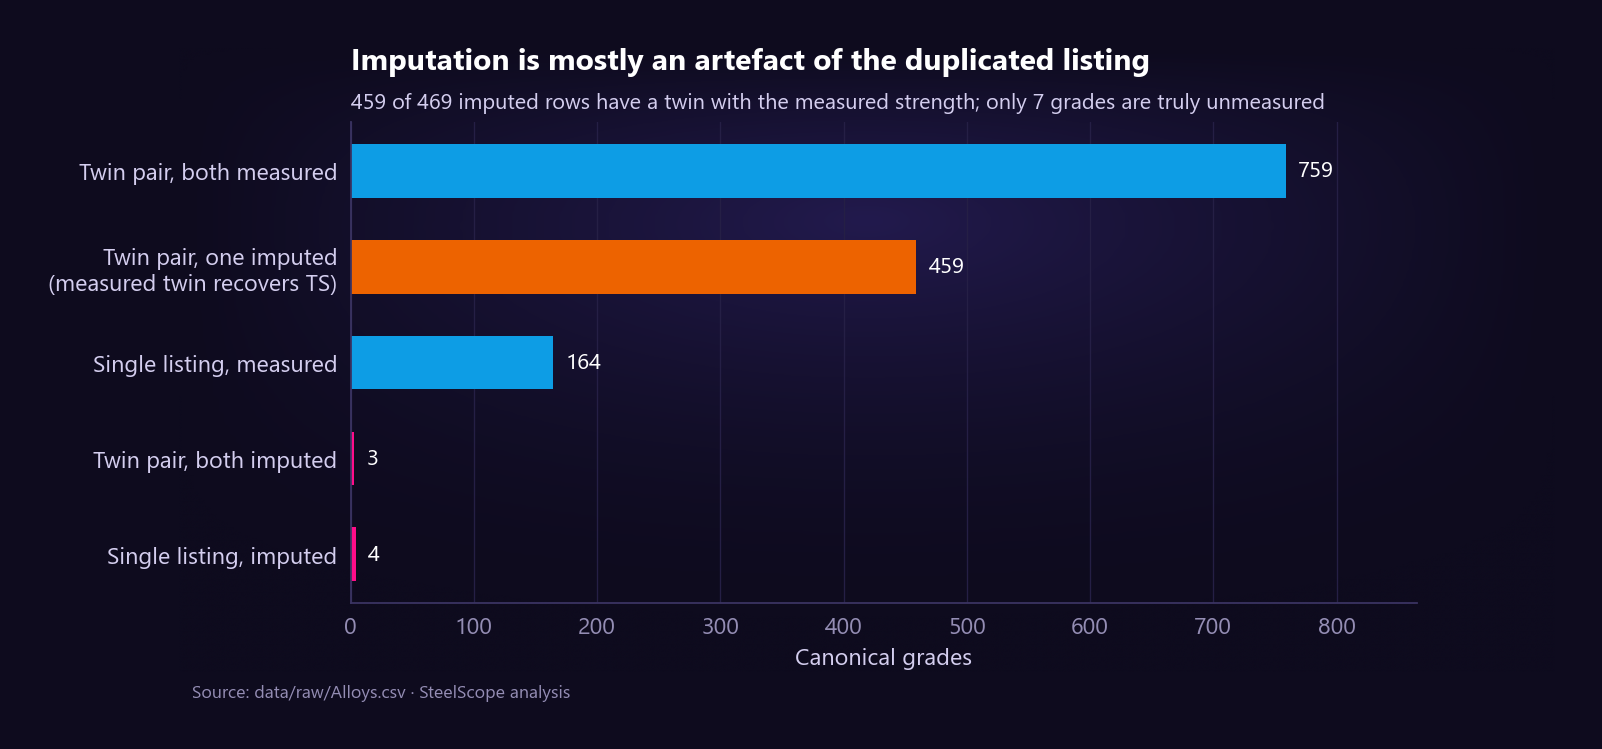

In [8]:
pv = listings.pivot_table(index="canonical_grade", columns="name_format", values="is_imputed_ts", aggfunc="first").dropna()
print(pd.crosstab(pv["spaced"], pv["hyphenated"], rownames=["spaced imputed"], colnames=["hyphenated imputed"]))
from src.analysis import viz_quality as VQ
show(VQ.twin_breakdown(listings), "01_twin_listings_imputation")

**Decision.** Collapse twins into one grade. Take TS from a measured listing whenever one exists. That is
not imputation: it is the same record's own value, and the twins never disagree. Grades with **no**
measured listing keep `is_imputed_ts = True`, have `tensile_strength_mpa = NaN`, and are excluded from every
strength statistic and model. They are kept for composition and family analysis.

In [9]:
m = log.get("collapse_to_grades").metrics
print("grades:", m["n_grades"], "| TS recovered from measured twin:", m["n_recovered_from_twin"],
      "| grades without any measured TS:", m["n_grades_without_measured_ts"])
grades.loc[grades.is_imputed_ts, ["display_name", "family", "n_listings"]]

grades: 1389 | TS recovered from measured twin: 459 | grades without any measured TS: 7


,display_name,family,n_listings
291,Austempered-Ductile-Cast-Iron,cast_iron_ductile,1
292,Automotive-Malleable-Cast-Iron,cast_iron_malleable,1
376,Ductile-Nodular-Spheroidal-Cast-Iron,cast_iron_ductile,1
697,EN 1.4710 (GX30CrSi7) Cast Stainless Steel,stainless,2
700,EN 1.4729 (GX40CrSi13) Cast Stainless Steel,stainless,2
702,EN 1.4740 (GX40CrSi17) Cast Stainless Steel,stainless,2
1001,Grey-Cast-Iron,cast_iron_grey,1


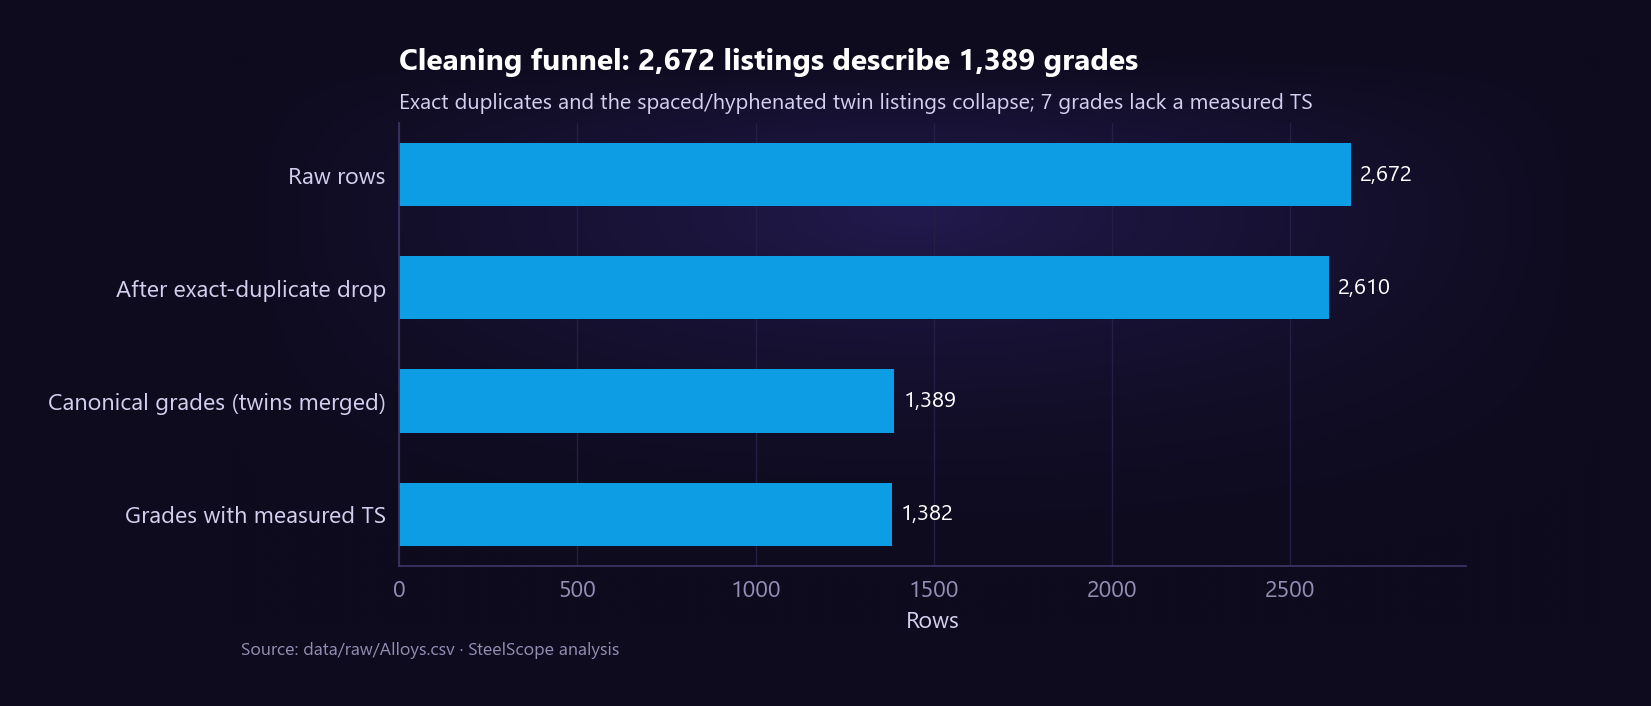

In [10]:
show(VQ.cleaning_funnel(log, int(grades.tensile_strength_mpa.notna().sum())), "01_cleaning_funnel")

## 6 · Identical composition, different strength: the irreducible error

Some compositions are listed with several strengths: maraging steel aged vs annealed, CB7Cu in H900…H1150
tempers, cast-iron grades poured from the same nominal chemistry. Strength there depends on
**processing / heat treatment, which the data does not record**. No composition-only model can separate
them, so their spread is the ceiling for any strength model (including the ones built in KNIME).

First, how many such groups are real and how many are an artefact of imputation?

In [11]:
log.get("audit_processing_variants").metrics

{'n_compositions': 1299,
 'groups_multi_ts_listing_level': 476,
 'groups_multi_ts_measured_only': 28,
 'grade_level_multi_member_groups': 37,
 'grade_level_groups_with_different_ts': 28}

In [12]:
from src.analysis.quality import irreducible_error
ie = irreducible_error(grades)
pd.Series(ie.as_dict())

oracle_mae                   9.908
oracle_rmse                 54.365
oracle_r2                    0.950
n_measured               1,382.000
n_groups                 1,296.000
multi_member_groups         37.000
multi_member_grades        123.000
groups_with_spread          28.000
within_group_mae           111.319
within_group_rmse          182.231
within_group_sd_pooled     217.934
dtype: float64

How to read the ceiling:

* **Whole-dataset oracle** (predict every grade with its composition-group mean, in-sample) gives the
  best MAE/RMSE/R² any composition-only model could reach. It is optimistic: singletons contribute zero
  error because their processing spread is simply unobserved.
* **Within multi-member groups** the floor is far higher. For grades sold in several tempers, chemistry
  alone cannot pin strength down to better than roughly this MAE.

,n,ts_min,ts_max,ts_range,family,example
composition_group_id,,,,,,
CG1255,3,"1,140.000","2,420.000","1,280.000",maraging,Aged Grade 350 Maraging Steel
CG1254,3,"1,030.000","2,030.000","1,000.000",maraging,Aged Grade 300 Maraging Steel
CG1196,8,860.000,"1,800.000",940.000,cast_iron_ductile,"ASTM A897 Grade 1 (ASTM 130-90-09 or 900-650-09, ISO 900-8) Cast Iron"
CG1252,3,970.000,"1,800.000",830.000,maraging,Aged Grade 250 Maraging Steel
CG1253,3,970.000,"1,500.000",530.000,maraging,Aged Grade 200 Maraging Steel
CG1055,9,460.000,920.000,460.000,cast_iron_ductile,"ASTM Grade 100-70-03 (SAE D7003, ISO 700-2, EN-JS 1070) Ductile Cast Iron"
CG0232,3,510.000,910.000,400.000,fe_ni_special,Annealed Type 2 Iron-Nickel Soft Magnetic Alloy
CG0259,7,960.000,"1,350.000",390.000,stainless,ACI-ASTM CB7Cu-2 (J92110) Cast Stainless Steel
CG0264,7,960.000,"1,350.000",390.000,stainless,ACI-ASTM CB7Cu-1 (J92180) Cast Stainless Steel


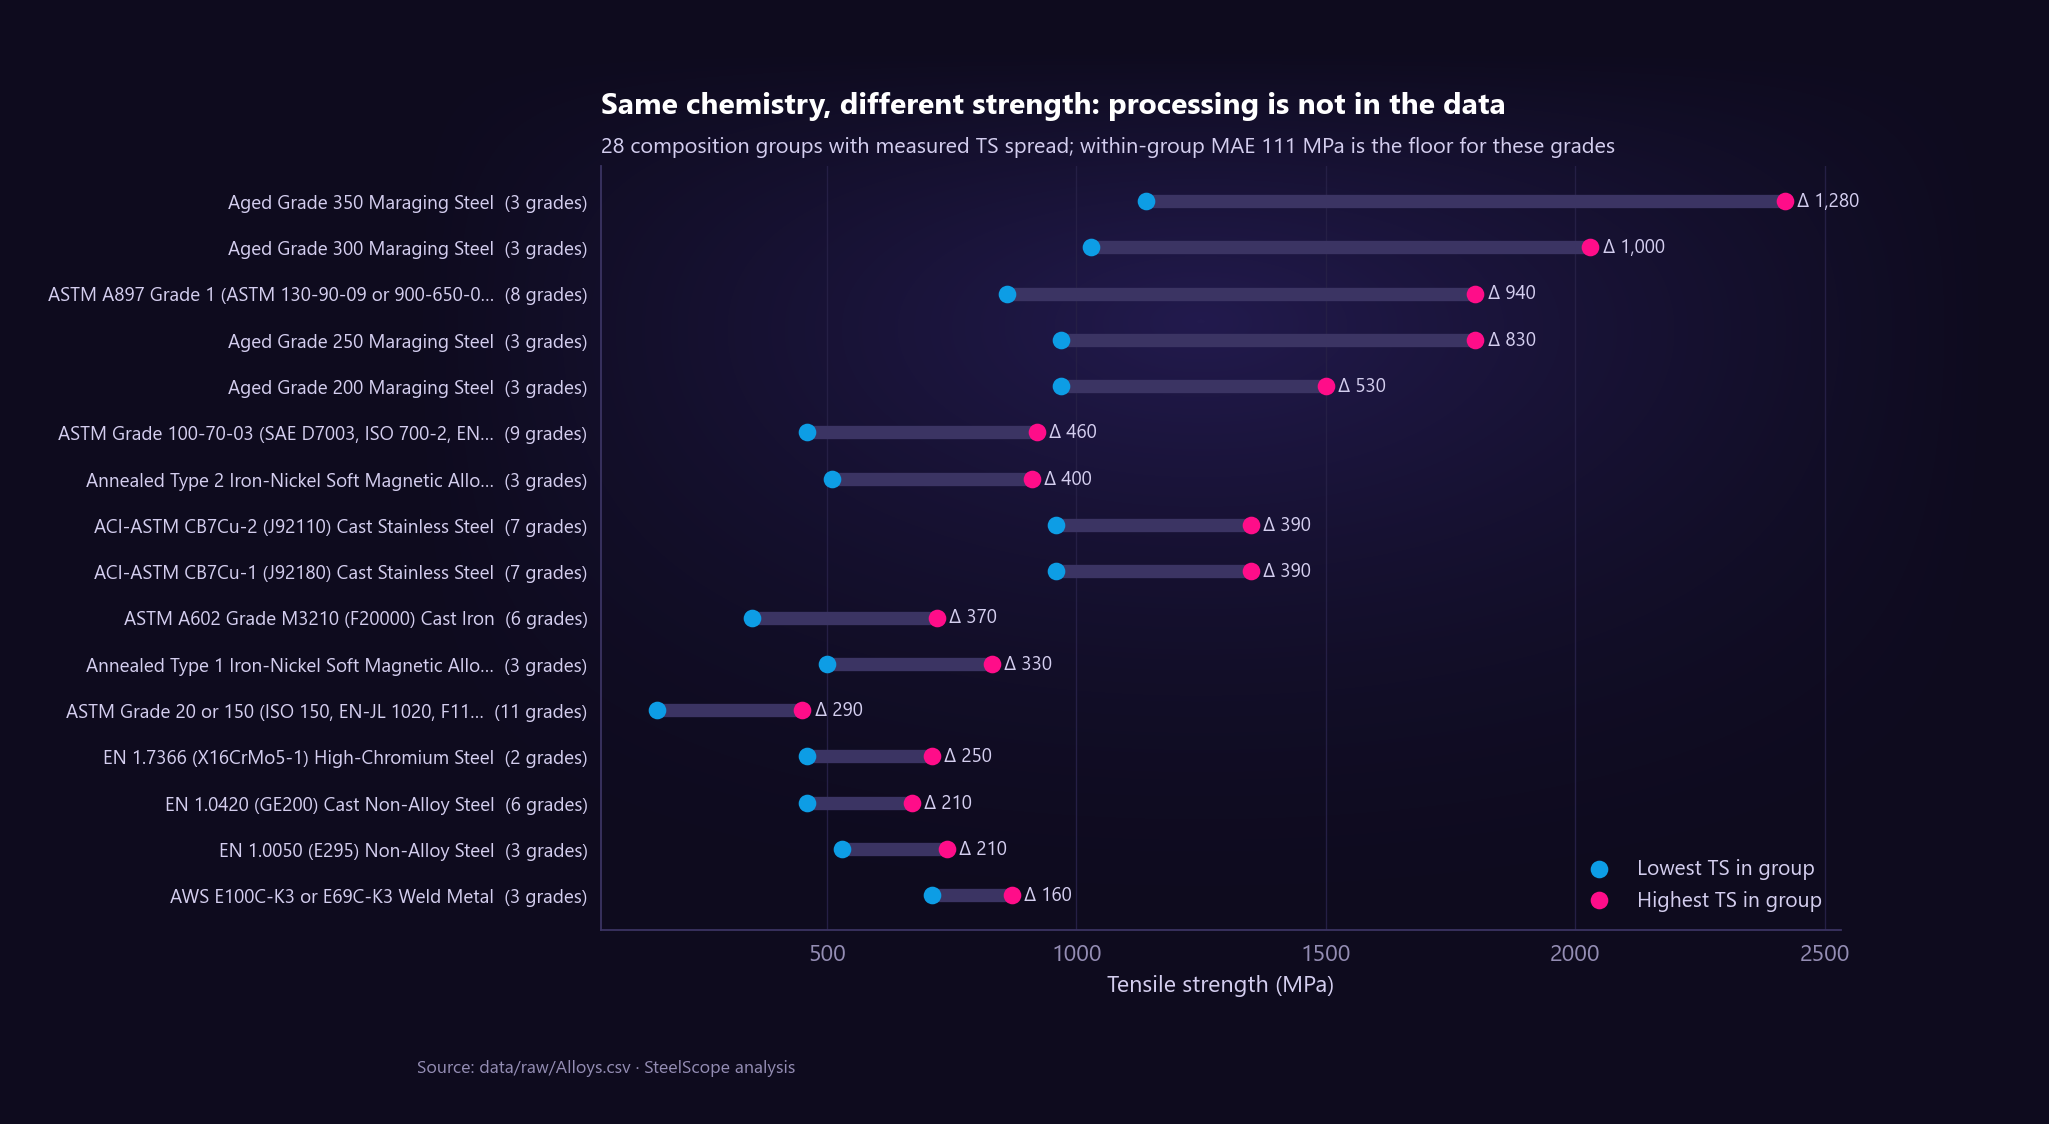

names stating a heat-treatment condition: {'precipitation_hardened': 12, 'annealed': 6, 'aged': 4, 'full_hard': 2, 'austempered': 1, 'oil_tempered': 1}


In [13]:
display(ie.groups[ie.groups.ts_range > 0][["n", "ts_min", "ts_max", "ts_range", "family", "example"]].head(12))
show(VQ.processing_variants(ie), "01_processing_variants")
print("names stating a heat-treatment condition:", grades.condition_in_name.value_counts().drop("none").to_dict())

## 7 · Strength class recomputed from measured TS

`Class` is binned TS (0 = 140–290, 1 = 300–600, 2 = 610–2450 MPa). We rebuild it from measured TS with the
same edges, check it reproduces the original on every measured listing, and leave it empty for unmeasured grades.

In [14]:
m = log.get("recompute_strength_class").metrics
print("agreement with original Class on measured listings:", m["agreement_on_measured_listings"])
print("grade-level class counts:", m["grade_class_counts"])
print("original listing-level class counts:", m["original_listing_class_counts"])

agreement with original Class on measured listings: 1.0
grade-level class counts: {'0': 23, '1': 648, '2': 711, '<NA>': 7}
original listing-level class counts: {'0': 23, '1': 998, '2': 1589}


## 8 · Is liquidus = 1460 °C a placeholder?

1460 °C is by far the most common liquidus. If it were measured, it should (a) fall as carbon rises in
plain steels (carbon depresses the liquidus), and (b) appear evenly across naming sources and name formats.

In [15]:
from src.analysis.quality import liquidus_default_evidence
ev = liquidus_default_evidence(grades, listings)
print("by name format (listings):"); display(ev.by_name_format)
print("by naming source (grades):"); display(ev.by_naming_source)

by name format (listings):


,n,n_1460,share_1460
name_format,,,
hyphenated,1302,522,0.401
spaced,1308,515,0.394


by naming source (grades):


,n,n_1460,distinct_liquidus,share_1460
naming_source,,,,
EN,606,305,17,0.503
SAE-AISI,318,128,32,0.403
UNS,146,19,14,0.130
ASTM,145,41,15,0.283
AWS,83,24,10,0.289
Other,46,3,10,0.065
ACI,45,4,9,0.089


In [16]:
print("by family (grades):"); display(ev.by_family)
print("carbon & low-alloy families, C <= 1 wt%: recorded vs empirical liquidus by carbon band")
display(ev.carbon_bins)
pd.Series(ev.summary)

by family (grades):


,n,n_1460,distinct_liquidus,share_1460
family,,,,
stainless,546,44,18,0.081
alloy,293,218,9,0.744
carbon,196,165,3,0.842
weld_metal,83,24,10,0.289
tool,53,12,17,0.226
boron,30,28,2,0.933
bearing,30,16,7,0.533
high_speed,29,0,17,0.000
cast_iron_grey,21,0,2,0.000


carbon & low-alloy families, C <= 1 wt%: recorded vs empirical liquidus by carbon band


,n,share_1460,recorded_mean,recorded_std,empirical_mean
C,,,,,
"(-0.001, 0.1]",170,0.753,"1,462.588",6.733,"1,519.082"
"(0.1, 0.2]",157,0.783,"1,461.720",6.322,"1,513.812"
"(0.2, 0.3]",60,0.967,"1,460.333",1.810,"1,507.692"
"(0.3, 0.45]",90,0.900,"1,458.667",4.293,"1,497.630"
"(0.45, 0.6]",71,0.606,"1,453.099",9.501,"1,484.944"
"(0.6, 1.0]",26,0.308,"1,474.231",76.429,"1,470.901"


n_grades_1460                                                                                                        524
share_grades_1460                                                                                                  0.377
n_listings_1460                                                                                                     1037
low_alloy_n                                                                                                          574
low_alloy_share_1460                                                                                               0.768
corr_C_vs_recorded_nondefault                                                                                     -0.081
corr_empirical_vs_recorded_nondefault                                                                              0.115
n_low_alloy_nondefault                                                                                               133
default_C_range                 

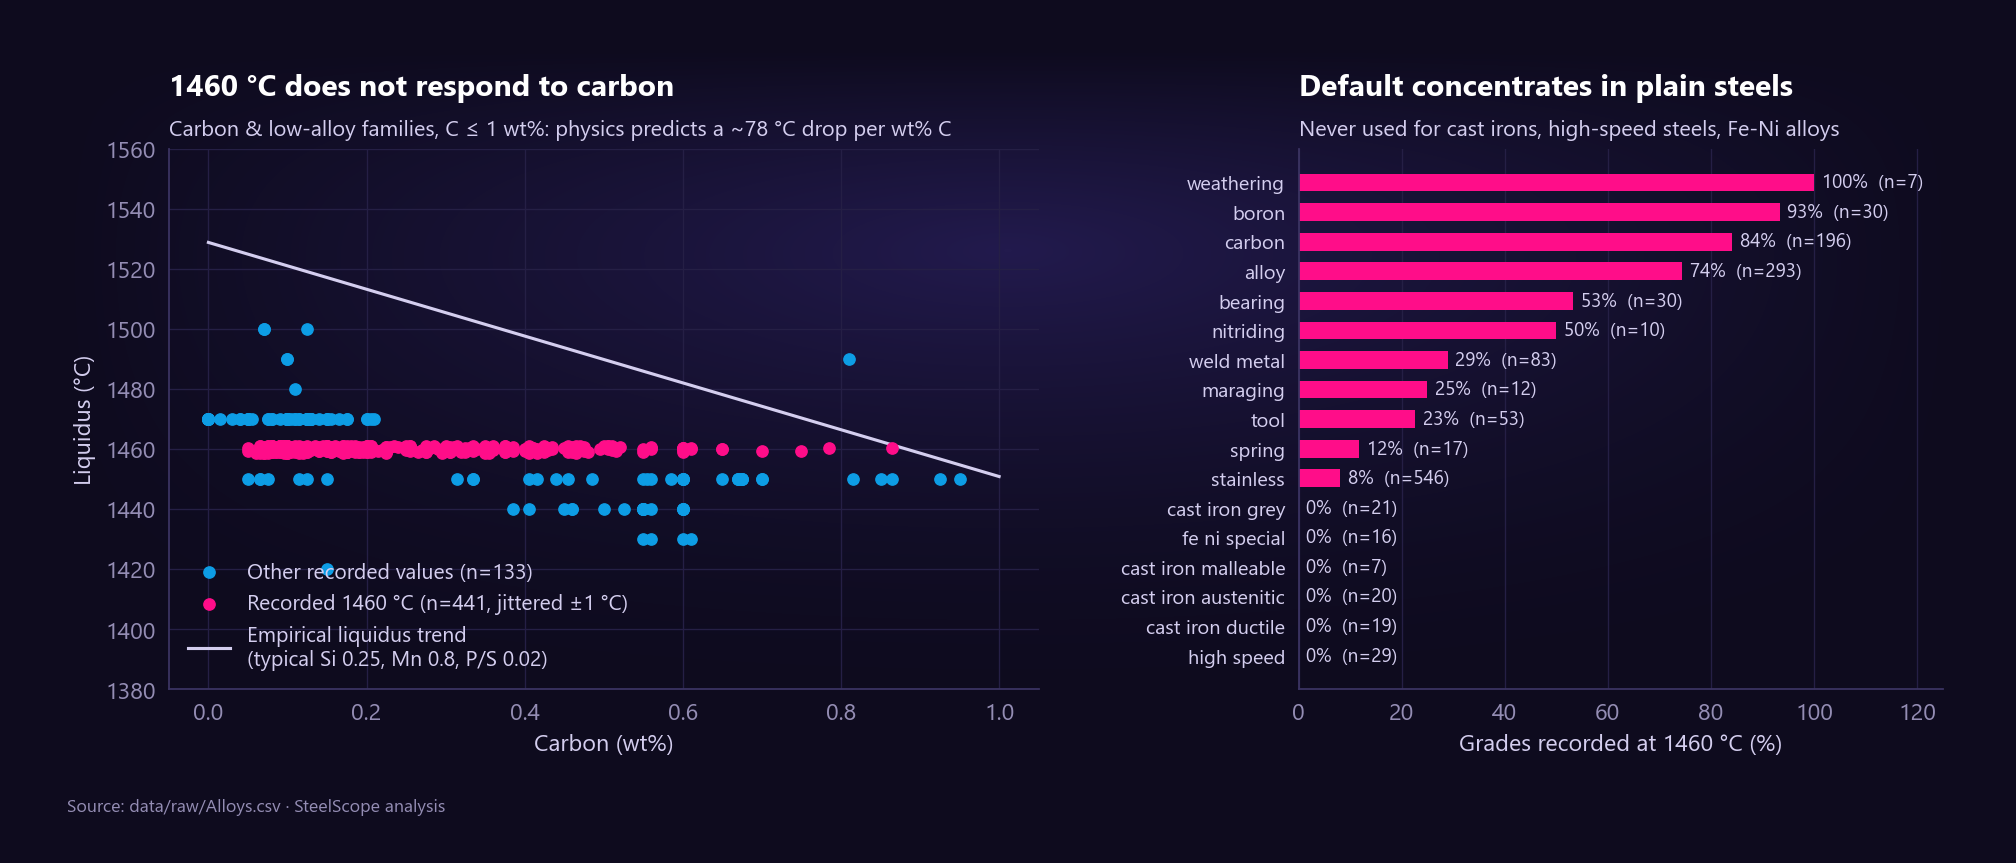

In [17]:
show(VQ.liquidus_default(ev), "01_liquidus_default")

**Findings.**

* The share of 1460 is the same in both name formats, so it is not a scrape artefact. It varies by
  naming source only because families vary by source.
* It is concentrated in plain carbon / low-alloy steels and never used for cast irons, high-speed steels
  or Fe-Ni alloys, whose liquidus values are clearly grade-specific.
* Within carbon & low-alloy steels the recorded liquidus barely moves across the carbon range, while the
  empirical liquidus correlation (and the Fe–C phase diagram) predicts a steady drop of tens of °C.
  Even the non-1460 values in these families show almost no correlation with carbon or with the empirical
  estimate (see `corr_*` above).

**Decision.** 1460 °C is a **family-typical default** assigned by the source, not a grade-specific
measurement. We **keep** it (it is a sensible typical value for plain steels), **flag** it as
`liquidus_is_default`, and treat liquidus as reliable only at family level for plain steels. Consequences:
no grade-level liquidus regression is claimed; the design-space analysis in notebook 02 shows default values
distinctly and can exclude them.

## 9 · Composition sums and trace elements

In [18]:
from src.analysis.quality import composition_sum_summary
print("composition sum:", composition_sum_summary(grades))
print(log.get("group_trace_elements").detail)
nonzero = (grades[ELEMENTS] > 0).sum().sort_values()
nonzero.to_frame("grades_nonzero").T

composition sum: {'min': 95.00999999999999, 'max': 105.23000000000002, 'median': 100.00999999999999, 'share_within_1pct': 0.9870410367170627, 'n_outside_1pct': 18}
10 elements non-zero in <30 de-duplicated rows summed into trace_total: As, Ca, Ce, La, Mg, Pb, Se, Sn, Ta, Zn


,Zn,Pb,La,Ta,Ce,As,Sn,Mg,Se,Ca,O,Zr,Co,B,W,Ti,Al,Nb,V,N,Cu,Mo,Ni,Cr,Si,S,Mn,P,C,Fe
grades_nonzero,1,3,5,5,10,10,12,12,13,14,25,46,53,87,90,194,211,227,299,423,560,838,926,1120,1309,1366,1369,1379,1380,1389


Sums of 95–105 wt% are expected: compositions are **specification midpoints**, rounded, with residual
elements omitted, not chemical analyses of a heat. We do not renormalise: renormalising would distort the
specified values engineers actually work with. Rare elements are kept as columns but summed into
`trace_total` for modelling, so a handful of non-zero values cannot dominate distances or splits.

## 10 · Engineered features

In [19]:
print(log.get("add_features").detail)
display(grades.groupby("family_label").agg(grades=("grade_id", "size"),
        measured_ts=("tensile_strength_mpa", "count"), median_ts=("tensile_strength_mpa", "median"),
        median_alloying=("alloying_total", "median"), median_CE=("carbon_equivalent", "median"))
        .sort_values("grades", ascending=False))
print("family assigned by:", grades.family_source.value_counts().to_dict())
print("naming source:", grades.naming_source.value_counts().to_dict())
print("product form:", grades.product_form.value_counts().to_dict())

family (17 families, 105 by EN 10020 composition rule), naming_source, product_form, CE, Cr+Ni, Schaeffler Cr/Ni eq, composition_group_id (1299 groups)


,grades,measured_ts,median_ts,median_alloying,median_CE
family_label,,,,,
Stainless steel,546,543,630.000,31.525,4.922
Alloy steel,293,293,590.000,2.900,0.618
Carbon / non-alloy steel,196,196,525.000,1.415,0.328
Weld metal,83,83,620.000,32.300,4.937
Tool steel,53,53,690.000,6.850,1.492
Boron steel,30,30,470.000,1.750,0.490
Bearing steel,30,30,625.000,2.925,0.832
High-speed steel,29,29,800.000,24.800,3.584
Grey cast iron,21,20,260.000,7.000,3.350


family assigned by: {'name': 1284, 'composition_rule': 105}
naming source: {'EN': 606, 'SAE-AISI': 318, 'UNS': 146, 'ASTM': 145, 'AWS': 83, 'Other': 46, 'ACI': 45}
product form: {'wrought': 1049, 'cast': 257, 'weld': 83}


| Feature | Definition | Why |
|---|---|---|
| `family` | Ordered name regex (weld metal, maraging and cast irons first), EN 10020 composition fallback | Engineers think in families; the family median is the natural baseline |
| `naming_source` | EN / SAE-AISI / ASTM / UNS / AWS / ACI / Other | Checks that defaults/imputation are not source artefacts |
| `product_form` | wrought / cast / weld | Cast and weld products have systematically different strength |
| `alloying_total` | 100 − Fe | "Leaner" substitutes = lower alloy content |
| `carbon_equivalent` | IIW: C + Mn/6 + (Cr+Mo+V)/5 + (Ni+Cu)/15 | Classic hardenability / weldability index |
| `cr_plus_ni`, `cr_eq`, `ni_eq` | Cr+Ni; Schaeffler equivalents | Stainless map and microstructure |
| `is_stainless_comp` | Cr ≥ 10.5 | Composition view of "stainless", independent of the name |
| `composition_group_id` | Identical 30-element vector | **GroupKFold key**: identical chemistry never straddles folds |

## 11 · Save

In [20]:
save_outputs(result)
for p in ["data/processed/steels_clean.csv", "data/processed/steels_listings.csv",
          "data/processed/DATA_DICTIONARY.md", "reports/cleaning_log.md"]:
    print(f"{p:42s} {(ROOT / p).stat().st_size / 1024:8.1f} KB")
grades.head(3)

data/processed/steels_clean.csv               591.7 KB
data/processed/steels_listings.csv            677.2 KB
data/processed/DATA_DICTIONARY.md               6.8 KB
reports/cleaning_log.md                         3.9 KB


,grade_id,canonical_grade,display_name,alt_name,n_listings,family,family_label,family_source,naming_source,product_form,condition_in_name,tensile_strength_mpa,is_imputed_ts,had_imputed_listing,strength_class,strength_class_label,liquidus_c,liquidus_is_default,Al,As,...,Se,Si,Sn,Ta,Ti,V,W,Zn,Zr,trace_total,comp_sum,alloying_total,carbon_equivalent,cr_plus_ni,cr_eq,ni_eq,is_stainless_comp,composition_group_id,composition_group_size,composition_group_n_measured
0,G0001,aci-astm-ca15-scs1-j91150-cast-stainless-steel,"ACI-ASTM CA15 (SCS1,J91150) Cast Stainless Steel",ACI-ASTM-CA15-SCS1-J91150-Cast-Stainless-Steel,2,stainless,Stainless steel,name,ACI,cast,none,700.000,False,False,2,High (>600 MPa),"1,440.000",False,0.000,0.000,...,0.000,0.750,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,100.015,14.850,2.792,13.250,14.125,3.000,True,CG0448,1,1
1,G0002,aci-astm-ca15m-j91151-cast-stainless-steel,ACI-ASTM CA15M (J91151) Cast Stainless Steel,ACI-ASTM-CA15M-J91151-Cast-Stainless-Steel,2,stainless,Stainless steel,name,ACI,cast,none,690.000,False,False,2,High (>600 MPa),"1,450.000",False,0.000,0.000,...,0.000,0.325,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,100.015,14.750,2.857,13.250,13.812,3.000,True,CG0449,1,1
2,G0003,aci-astm-ca28mwv-j91422-cast-stainless-steel,ACI-ASTM CA28MWV (J91422) Cast Stainless Steel,ACI-ASTM-CA28MWV-J91422-Cast-Stainless-Steel,2,stainless,Stainless steel,name,ACI,cast,none,"1,080.000",False,False,2,High (>600 MPa),"1,470.000",False,0.000,0.000,...,0.000,0.500,0.000,0.000,0.000,0.250,1.100,0.000,0.000,0.000,100.070,16.400,3.035,12.500,13.600,8.325,True,CG0705,1,1
